# Applied Statistics Assessment: Iris Petal Analysis 

In [1]:
# Numerical arrays and calculations
import numpy as np

# Data loading and grouping
import pandas as pd

# Plotting
import matplotlib.pyplot as plt

# Statistical functions and tests
from scipy import stats

## Problem 1: Exploring Petal Length

Problem 1 involves using the Iris dataset to investigate the distribution of petal length by doing the following:

1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an apppropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create seperate histograms for each of the three species, and superimpose an appropriate distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distribution observed. And discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

### Loading the data
The Iris dataset that has 150 samples from three types of iris flowers: setosa, versicolor, and virginica.For each flower the dataset records the sepal length, sepal width, petal length, and petal width.

I loaded the data from the local `data` folder of this repository.

The CSV file is the one linked from the assessment brief, hosted in the seaborn-data repository (see References).

In [2]:
# Load the Iris dataset from the data folder
iris = pd.read_csv("data/iris.csv")

# Show the first few rows to check the colmns loaded correctly
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Check the number of rows and the number of flowers per species
print(iris.shape)
print(iris["species"].value_counts())

(150, 5)
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### Histogram of all 150 flowers
To investigate the distribution of petal length, I plot a histogram of all 150 measurements.

I set `density=True` so the bar heights are scaled to a total area of 1. This puts the histogram on the same scale as a probability density function. 

I then overlay a normal curve (`scipy.stats.norm.pdf`) whose mean and standard deviation are calculated from the data. If the data were approximately normal, the curve would follow the shape of the bars.

In [4]:
# Select the petal length column
petal_length = iris["petal_length"]

# Mean and sample standard deviation (ddof=1) of all 150 flowers
mean_all = petal_length.mean()
std_all = petal_length.std(ddof=1)

print(f"Mean: {mean_all:.3f}, standard deviation: {std_all:.3f}")

Mean: 3.758, standard deviation: 1.765


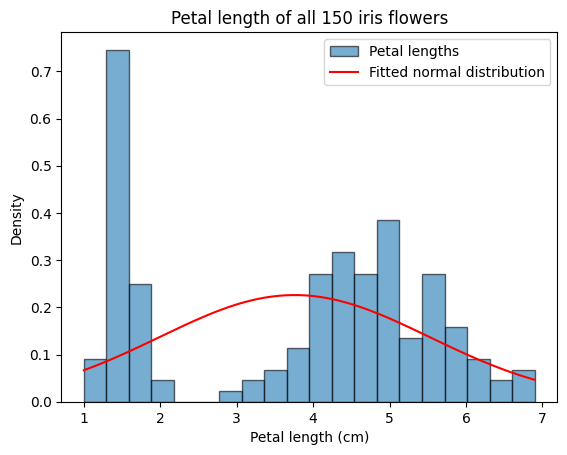

In [5]:
# Histogram of petal length, scaled so the total area is 1
fig, ax = plt.subplots()
ax.hist(petal_length, bins=20, density=True, alpha=0.6, edgecolor="black", label="Petal lengths")

# Evenly spaced x values across the range of the data
x = np.linspace(petal_length.min(), petal_length.max(), 200)

# Normal curve using the mean and standard deviation from the data
ax.plot(x, stats.norm.pdf(x, mean_all, std_all), color="red", label="Fitted normal distribution")
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Density")
ax.set_title("Petal length of all 150 iris flowers")
ax.legend()
plt.show()

The histogram is not a single bell shape. There is a tall, narrow group of flowers with petal lengths between about 1 and 2 cm, a clear gap between roughly 2 and 3 cm where there are almost no flowers, and a second, wider group spread from about 3 to 7 cm, with most flowers between 4 and 6 cm. The fitted normal curve is low and wide, and its peak (near 3.8 cm) falls in the region between the two groups where there are very few flowers. It underestimates the height of the setosa-like spike on the left and does not follow the shape of the main group on the right. A single normal distribution is therefore a poor model for petal length across all 150 flowers. This suggests the data come from more than one population.

### Mean and standard deviation by species
To model each species separately, I first calculate the mean and sample standard deviation of petal length for the complete dataset and for each species.

In [6]:
# Mean and sample standard deviation (ddof=1) of petal length per species
species_stats = iris.groupby("species")["petal_length"].agg(["mean", "std"])

# Add a row for the complete dataset so everything sits in one table
species_stats.loc["all flowers"] = [mean_all, std_all]

# Round to three decimal places for readability
species_stats.round(3)

,mean,std
species,,
setosa,1.462,0.174
versicolor,4.260,0.470
virginica,5.552,0.552
all flowers,3.758,1.765


Setosa has the shortest petals (mean 1.462 cm) and a very small standard deviation (0.174 cm), so its petals are tightly clustered. Versicolor has a mean of 4.260 cm (standard deviation 0.470 cm) and virginica about 5.552 cm (standard deviation 0.552 cm). Within each species the spread is much smaller than the overall standard deviation of about 1.765 cm, which means most of the overall variation comes from differences between species and not from variation with them.

### Histograms by species
I now plot a seperate histograms for each species, with a normal curve fitted using the species' own mean and standard deviation. Each plot uses the same x-axis range so the species can be compared directly.

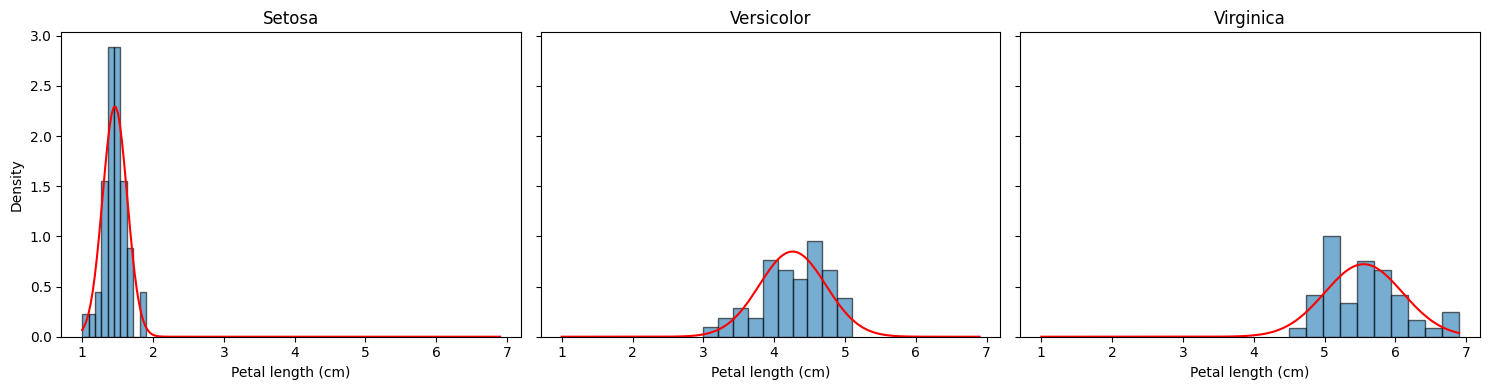

In [7]:
# Three side-by-side plots sharing the same x and y axis for easy comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

# Common x values covering the full range of petal lengths
x = np.linspace(petal_length.min(), petal_length.max(), 200)

for ax, (species, group) in zip(axes, iris.groupby("species")):
    lengths = group["petal_length"]
    mean = lengths.mean()
    std = lengths.std(ddof=1)

    # Density histogram and fitted normal curve for this species
    ax.hist(lengths, bins=10, density=True, alpha=0.6, edgecolor="black")
    ax.plot(x, stats.norm.pdf(x, mean, std), color="red")

    ax.set_title(species.capitalize())
    ax.set_xlabel("Petal length (cm)")

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

Each species forms a single, roughly symmetric group, and the fitted normal curves follow the bars well. Setosa is a very narrow peak around 1.5 cm, versicolor is centered near 4.3 cm, and virginica near 5.6 cm. The histograms are little uneven because each species has only 50 flowers, and a few bars in versicolor and virginica sit above or below their curves. The three groups overlap slightly, mainly versicolor and virginica between about 4.5 and 5.1 cm, while setosa is completely seperate from the other two.

### Discussion: is a normal distribution a reasonable model?
Across all 150 flowers, petal length is described well by normal distribution. The histogram has two groups: a narrow peak of short petals at about 1 to 2 cm, and a wider group from about 3 to 7 cm, with an almost empty gap between them. The fitted curve (mean 3.758 cm, standard deviation 1.765 cm) peaks in that gap and misses both groups.

Within each species the picture is very different. Setosa (mean 1.462 cm, standard deviation 0.174 cm), versicolor (mean 4.260 cm, standard deviation 0.470 cm) and viriginica (mean 5.552 cm, standard deviation 0.552 cm) each form a single, roughly symmetric group, and their fitted normal curves follow the bars reasonably well. A normal distribution is therefore a reasonable model for each species, although with only 50 flowers per group the histograms are somewhat uneven and a few bars sit above or below the curve.

Comparing the species, setosa has the shortest and most tightly clustered petals and its completely separate from the others. Versicolor and virginica have larger means and larger spreads, and their distributions overlap between about 4.5 and 5.1 cm. The large overall standard deviation (1.765 cm) comes mainly from the differences between species and not from variation within them. This is why the combined data look non-normal even though each species on its own is close to normal.

### References
- Waskom, M. seaborn-data repository, [`iris.csv`](https://github.com/mwaskom/seaborn-data/blob/master/iris.csv). This is the CSV copy of the Iris dataset linked from Problem 1 of the assessment brief, saved in the `data` folder and loaded in this notebook.
- SciPy documentation: [`scipy.stats.norm`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html). I use the `pdf` method to draw the fitted normal curves over the histograms.
- pandas documentation: [`DataFrame.grouby`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html). I use this to calculate statistics and draw a histogram for each species.

## Problem 2: Correlation Between Petal Length and Petal Width

Problem 2 involves investigateing the relationship between petal length and petal width in the Iris dataset by doing the following:

1. Calculating teh Pearson correlation coefficient between petal length adn petal width using all 150 flowers.
2. Create a scatter plot showing the relationship between the two variables, with a line to help illustrate the relationship.
3. Calculate the Pearson correation coefficient seperately for each of the three species.
4. Create a plot showing the relationship between petal length and petal width for each species.
5. Report and compare the correlation coefficients.
6. Explain what the correlation coefficients says about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

### Correlation across all 150 flowers
To measure the linear relationship between petal length and petal width, I calculate the Pearson correlation coefficient using `scipy.stats.pearsonr`. The coefficient ranges from -1 to 1. A value close to 1 means that flowers with longer petals tend to have wider petals, and a value close to 0 means there is no linear relationship. I start with all 150 flowers combined.

In [8]:
# Pearson correlation between petal length and petal width for all 150 flowers.
result_all = stats.pearsonr(iris["petal_length"], iris["petal_width"])
r_all = result_all.statistic

print(f"Pearson r (all flowers): {r_all:.3f}")
print(f"p-value: {result_all.pvalue:.3g}")

Pearson r (all flowers): 0.963
p-value: 4.68e-86


The Pearson correlation coefficient between petal length and petal width across all 150 flowers is 0.963. This is very close to 1, so there is a very strong positive linear relationship: flowers with longer petals almost always have wider petals. The p-value (4.68e-86) is far below 0.05, so this correlation is extremely unlikely to have arisen by chance. This is the correlation for the combined data.

### Scatter plot of petal length and petal width
To see the relationship, I plot petal width against petal length for all 150 flowers. I add a least-squares line of bext fit, calculated with `scipy.stats.linregress`, to show the overall trend.

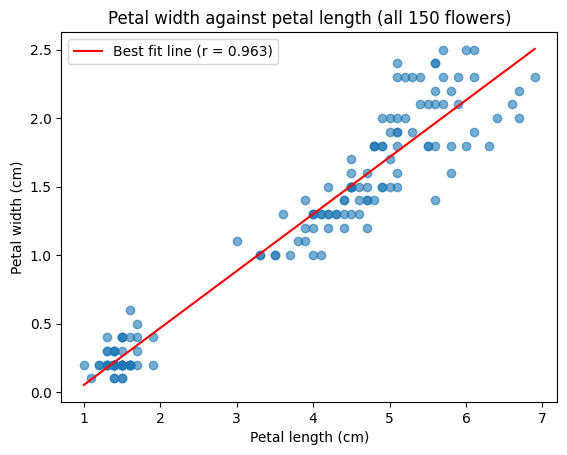

In [9]:
# Least-squares line of best fit for all 150 flowers
fit = stats.linregress(iris["petal_length"], iris["petal_width"])

# Scatter plot of every flower
fig, ax = plt.subplots()
ax.scatter(iris["petal_length"], iris["petal_width"], alpha=0.6)

# Evenly spaced x values across the ranges of petal lengths
x_line = np.linspace(iris["petal_length"].min(), iris["petal_length"].max(), 100)

# Draw the fitted line: y = slope * x + intercept
ax.plot(x_line, fit.slope * x_line + fit.intercept, color="red", label=f"Best fit line (r = {r_all:.3f})")

ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("Petal width against petal length (all 150 flowers)")
ax.legend()
plt.show()

The scatter plot shows a strong positive linear relationship between petal length and petal width: as petal length increases, petal width increases. The points fall close to the red line of best fit, which matches the correlation of 0.963 calculated earlier. The points form two groups. A tight cluster of flowers has short, narrow petals (length below about 2 cm and width below about 0.6 cm), and a larger, more spread-out group has petals from about 3 to 7 cm long and 1 to 2.5 cm wide. There is a clear gap between the two groups. Within the larger group the points are more scattered around the line, especially at lengths above 5 cm.

### Correlation within each species
The overall correlation combines three different species. To check whether the relationship also holds within each species, I calculate the Pearson correlation coefficient seperately for setosa, versicolor and virginica.

In [10]:
# Pearson correlation between petal length and petal width for each species
species_r = {}
for species, group in iris.groupby("species"):
    species_r[species] = stats.pearsonr(group["petal_length"], group["petal_width"]).statistic

# Add the overall value so all four are in one table
species_r["all flowers"] = r_all

# Show as a table, rounded to three decimal places
corr_table = pd.Series(species_r, name="Pearson r").round(3).to_frame()
corr_table

,Pearson r
setosa,0.332
versicolor,0.787
virginica,0.322
all flowers,0.963


The Pearson correlation coefficient is 0.963 for all 150 flowers, but it is much lower within each species: 0.332 for setosa, 0.787 for versicolor and 0.322 for virginica. All three species-level values are positive, so petal width tends to increase with petal length within every species. Versicolor shows a fairly strong relationship (0.787), while setosa and virginica show only weak to moderate relationship (about 0.33 and 0.32). The overall correlation is therefore much higher than any of the within-species values. This is because the three species have very different average petal sizes: setosa has short, narrow petals, and versicolor and virginica have progressively longer, wider ones. These differences between species produce a strong overall trend, even though the relationship between length and width within a species is weaker.

### Scatter plots by species
To see the relationship within each species, I plot petal width against petal length in three panels, one per species, each with its own line of best fit. All three panels use the same axes so the species can be compared directly.

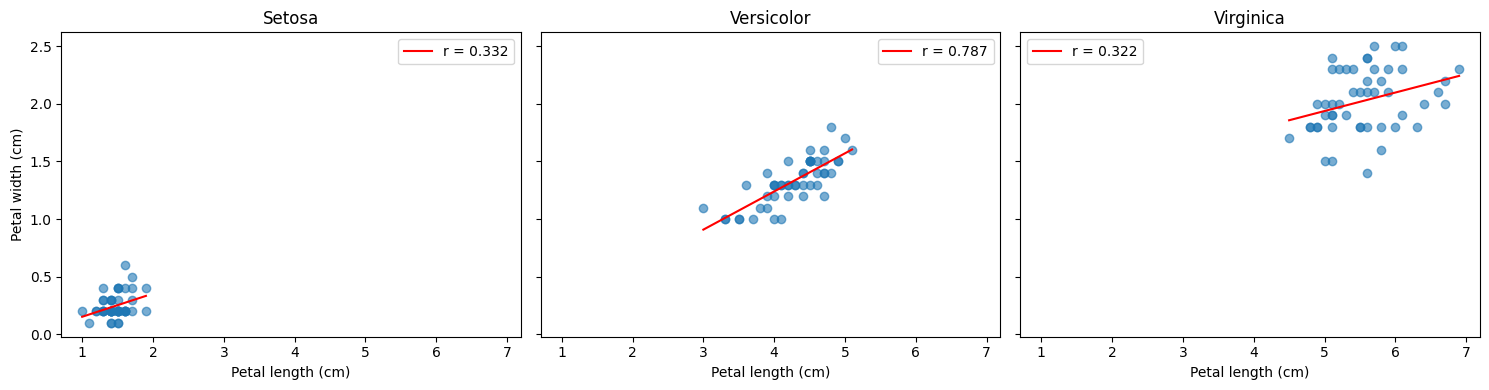

In [11]:
# Three side-by-side scatter plots sharing the same axes for easy comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for ax, (species, group) in zip(axes, iris.groupby("species")):
    length = group["petal_length"]
    width = group["petal_width"]

    # Line of best fit for this species only
    species_fit = stats.linregress(length, width)
    x_line = np.linspace(length.min(), length.max(), 100)

    ax.scatter(length, width, alpha=0.6)
    ax.plot(x_line, species_fit.slope * x_line + species_fit.intercept, color="red", label=f"r = {species_r[species]:.3f}")

    ax.set_title(species.capitalize())
    ax.set_xlabel("Petal length (cm)")
    ax.legend()

axes[0].set_ylabel("Petal width (cm)")
plt.tight_layout()
plt.show()

## Problem 3: Comparing Species Using t-Tests

Problem 3 involves investigating whether the three iris species differ in their petal length and petal width by doing the following:

1. For each pair of species perform an independant-samples t-test for petal length, petal width.
2. For each test:
   - State the null and alternative hypotheses.
   - Calculate the t-statistic and p-value using scipy.stats.
   - Use a significance level α = 0.05 to decide whether to reject the null hypothesis.
   - Summarise results in a table.
   - Explain what the results say about the differences between the three species.

## Problem 4: Comparing the Species Using ANOVA

Problem 4 involves investigating the differences in petal length and petal width using one-way analysis of variance (ANOVA) for each variable by:

1. Stating the null and alternative hypotheses for a one-way ANOVA.
2. Performing a one-way ANOVA comparing the three species using scipy.stats.
3. Reporting the F-statistic and p-value.
4. Using significant level α = 0.05 determine whether there is evidence that the species have different population means.
5. Explaining what the ANOVA results say and what it doesnt say about the individual species.

## End